In [1]:
# ---- Importing Media --- #
from media import medium_helper

SiN = medium_helper.get_medium(
    "si3n4",
    (0.600, 1.200),
)

SiO2 = medium_helper.get_medium(
    "sio2",
    (0.600, 1.200)
)

2026-07-23 15:54:38,174 - media.medium_helper - INFO - [Medium] Loading si3n4 cached fit from Luke_Si3N4.json...
2026-07-23 15:54:38,176 - media.medium_helper - INFO - [Medium] Loading sio2 cached fit from Nyakuchena_fusedSilica.json...


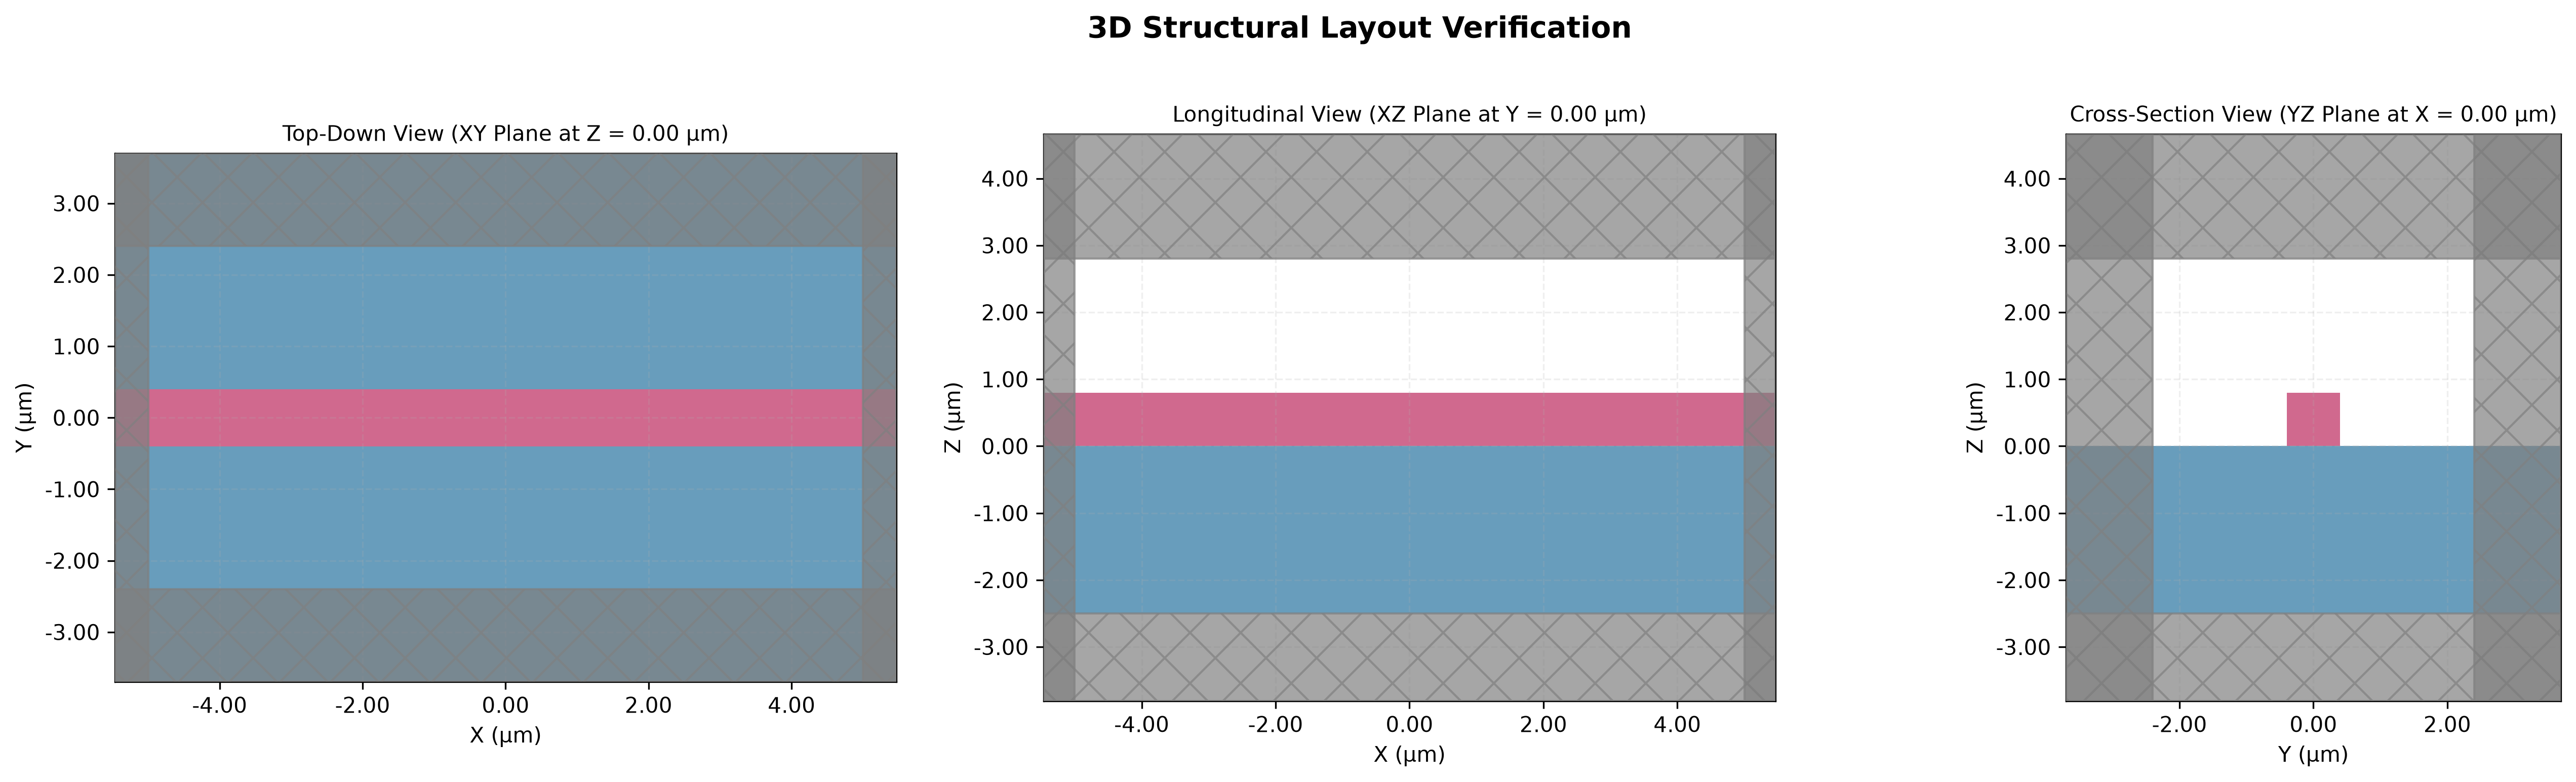

2026-07-23 15:54:39,580 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_passive_waveguide


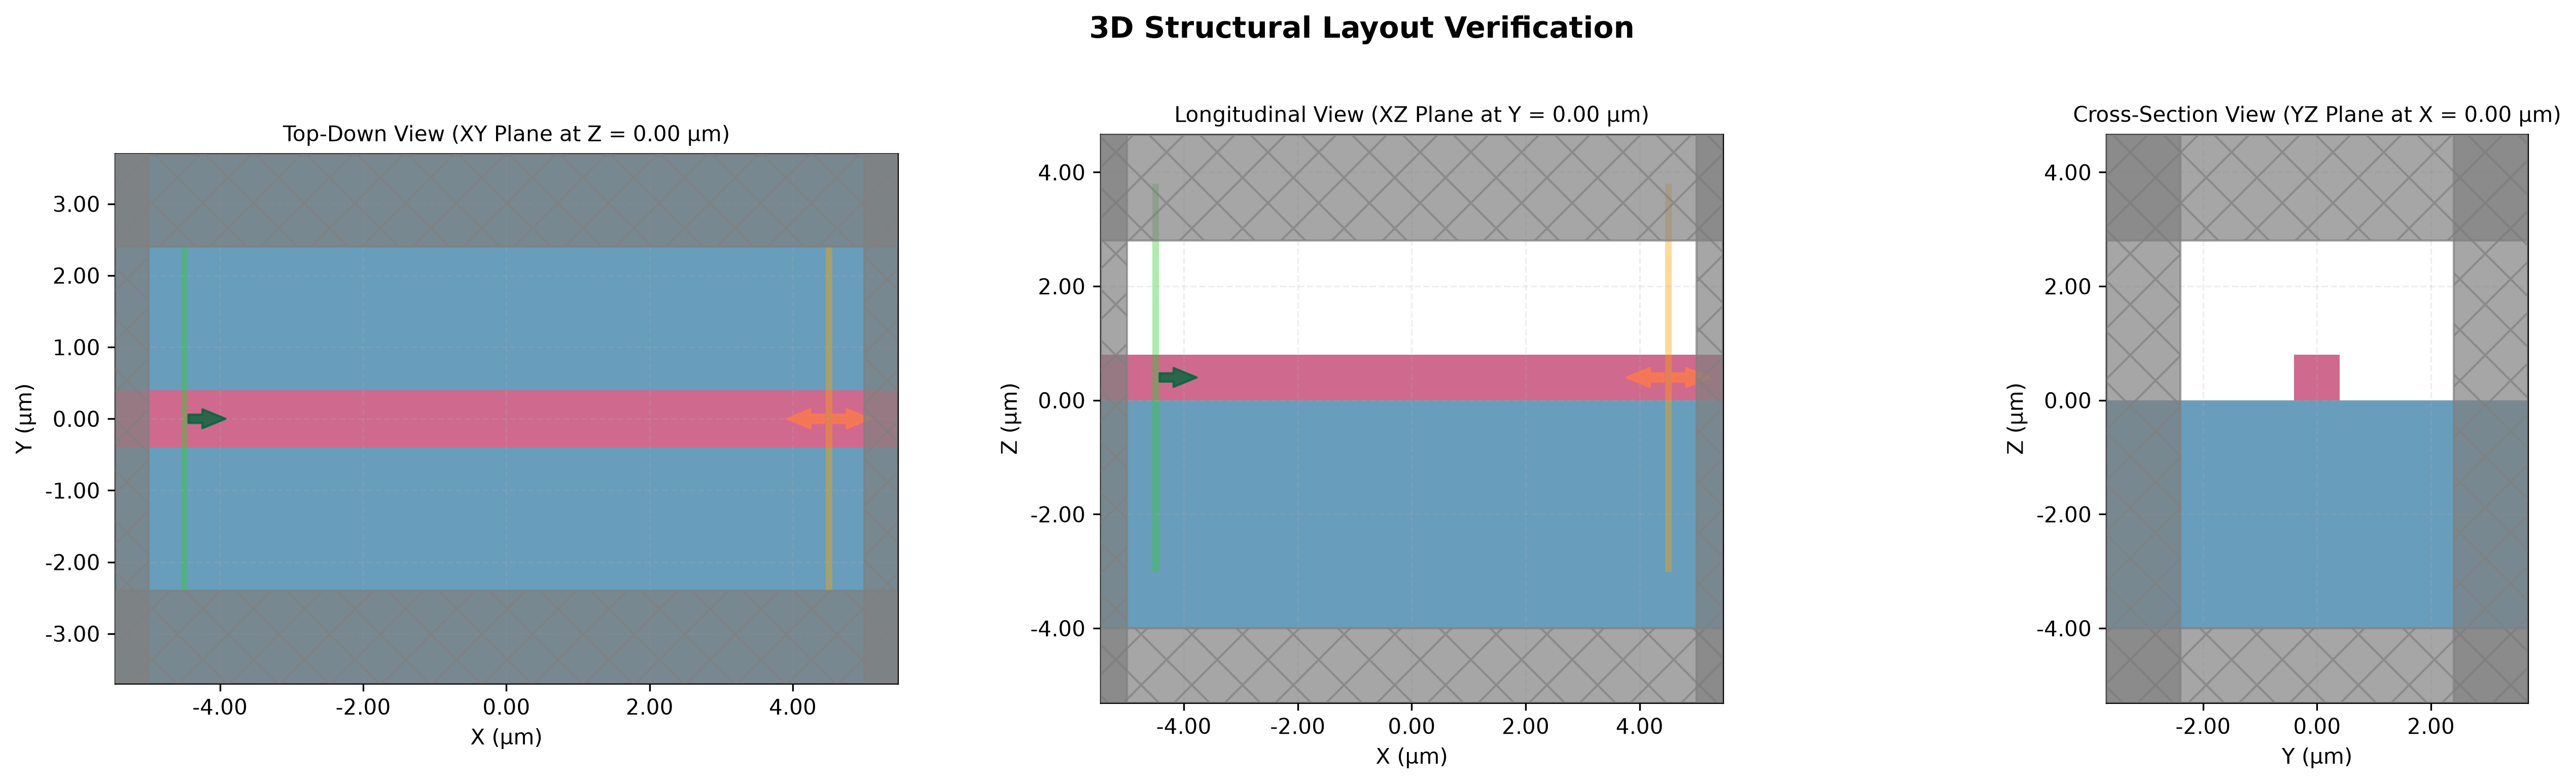

2026-07-23 15:54:40,247 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_active_waveguide


In [2]:
# ---- Waveguide Geometry Tests ---- #
from geometries import ridge_waveguide
from utilities import sim_plotter

from pathlib import Path 

example_passive_waveguide = ridge_waveguide.get_passive_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,
    
    substrate_height = 2.5,
    
    core_medium=SiN,
    sub_medium=SiO2,
)

# The active ridge waveguide features a mode source and a mode monitor
# which the passive simulation otherwise lacks.
example_active_waveguide = ridge_waveguide.get_active_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,

    substrate_height = 4.0,
    
    core_medium=SiN,
    sub_medium=SiO2,
)

# ---- Plotting to Verify Geometry ---- #
sim_plotter.display_3d(example_passive_waveguide, output_path = Path("example_passive_waveguide"), show = True)
sim_plotter.display_3d(example_active_waveguide, output_path = Path("example_active_waveguide"), show = True)

### Analysis

In [3]:
# ---- Analysis of a Defined Geometry ---- #
from geometries import ridge_waveguide
from pprint import pprint

waveguide_1550 = ridge_waveguide.get_passive_simulation(
    width = 0.800,
    height = 0.800,

    length = 2.0,

    core_medium = SiN,
    sub_medium = SiO2,
    substrate_height = 4.0,

    wavelength_um = 1.550
)

print("----- Mode Analysis -----")
pprint(waveguide_1550.get_modes())
print("----- -----\n\n")

print("----- Dispersion Analysis -----")
pprint(waveguide_1550.get_dispersion())
print("----- -----\n\n")

print("----- Confinement Analysis -----")
pprint(waveguide_1550.get_confinement())
print("----- -----\n\n")

----- Mode Analysis -----
2026-07-23 15:54:40,367 - waveguide.waveguide - INFO - [Mode Engine] Solving top 8 modes for W=0.800 μm, H=0.800 μm...
{'height_um': 0.8,
 'modes': [{'is_guided': True,
            'mode_index': 0,
            'neff': 1.665563999556983,
            'polarization': 'TM',
            'te_fraction': 0.009247309230921593},
           {'is_guided': True,
            'mode_index': 1,
            'neff': 1.6426207257762198,
            'polarization': 'TE',
            'te_fraction': 0.9863217438506641},
           {'is_guided': False,
            'mode_index': 2,
            'neff': 1.3699171496811269,
            'polarization': 'TM',
            'te_fraction': 0.022548946018185904},
           {'is_guided': False,
            'mode_index': 3,
            'neff': 1.3215362715606576,
            'polarization': 'TE',
            'te_fraction': 0.8873830868099074},
           {'is_guided': False,
            'mode_index': 4,
            'neff': 1.284313363872637,
   

### Sweep Analysis

2026-07-23 15:57:13,481 - media.medium_helper - INFO - [Medium] Loading si3n4 cached fit from Luke_Si3N4.json...
2026-07-23 15:57:13,485 - media.medium_helper - INFO - [Medium] Loading sio2 cached fit from Nyakuchena_fusedSilica.json...
2026-07-23 15:57:13,487 - root - INFO - 
[Mode Analysis] Plotting mean geometry (Width: 0.50 um, Height: 0.77 um)...


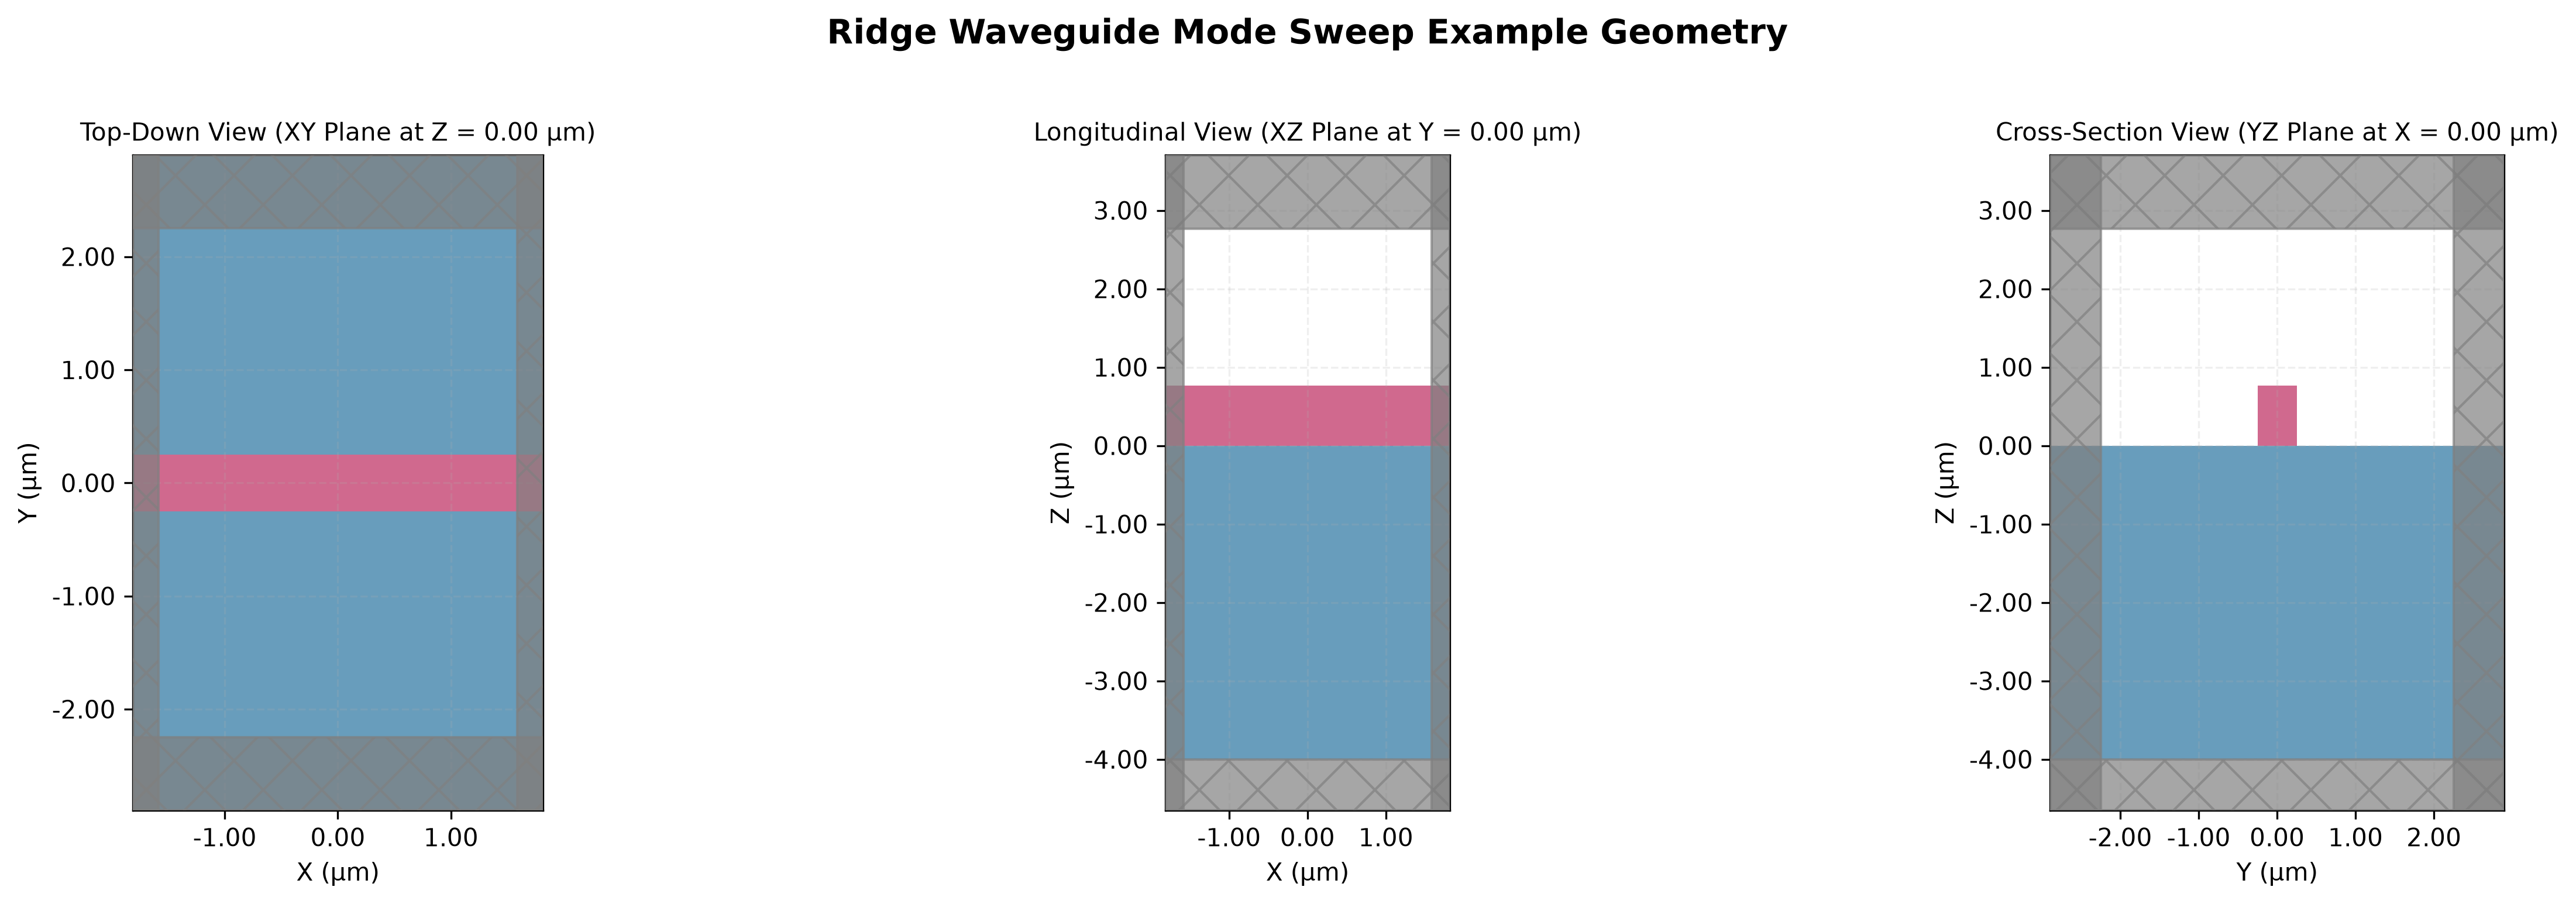

2026-07-23 15:57:14,227 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/waveguide/mode_sweep/example_geometry.png
2026-07-23 15:57:14,228 - root - INFO - 
[Mode Analysis] | Height: 0.50 um at 780 nm


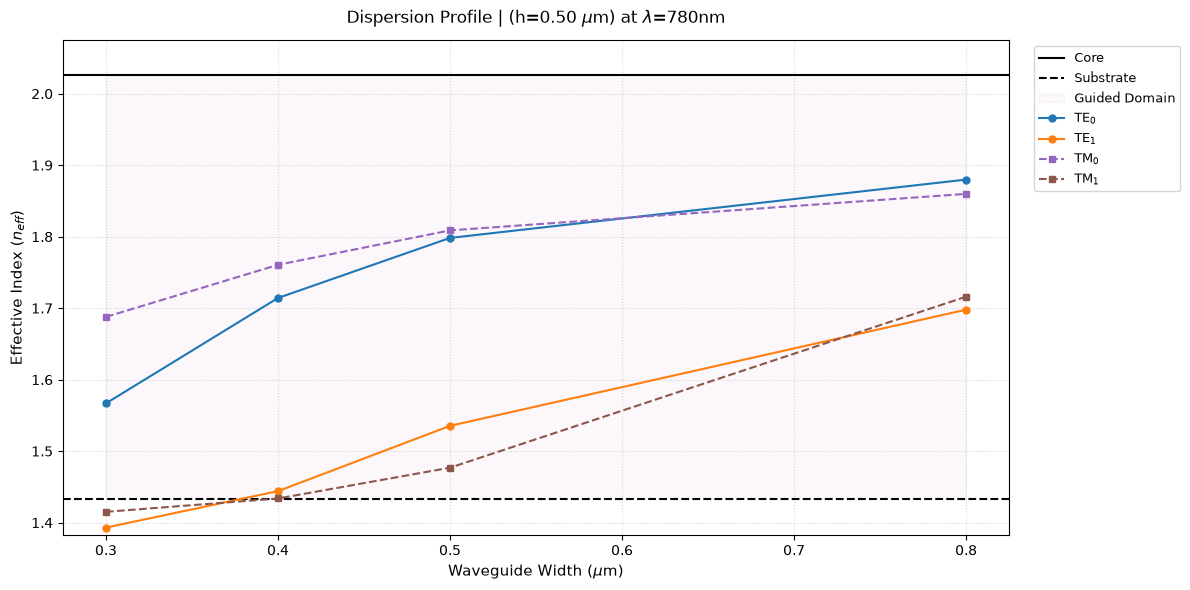

2026-07-23 15:57:20,836 - root - INFO - [Mode Analysis] Visualized distribution out to 780nm_wgW_0.80_wgH_0.50um.png
2026-07-23 15:57:20,837 - root - INFO - 
[Mode Analysis] | Height: 0.80 um at 780 nm


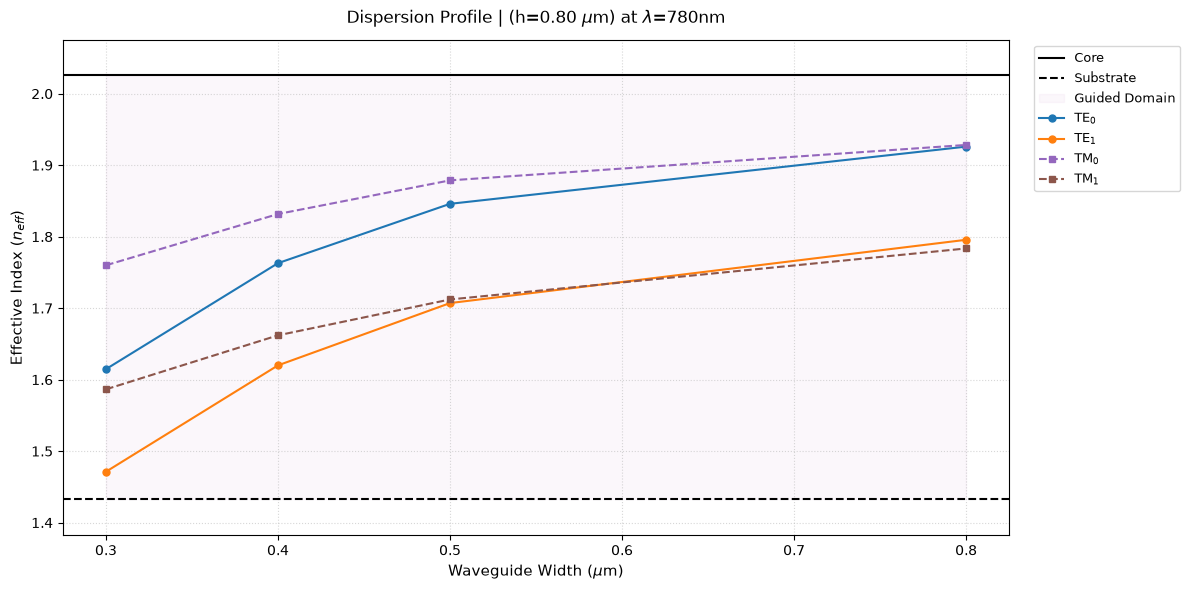

2026-07-23 15:57:29,959 - root - INFO - [Mode Analysis] Visualized distribution out to 780nm_wgW_0.80_wgH_0.80um.png
2026-07-23 15:57:29,959 - root - INFO - 
[Mode Analysis] | Height: 1.00 um at 780 nm


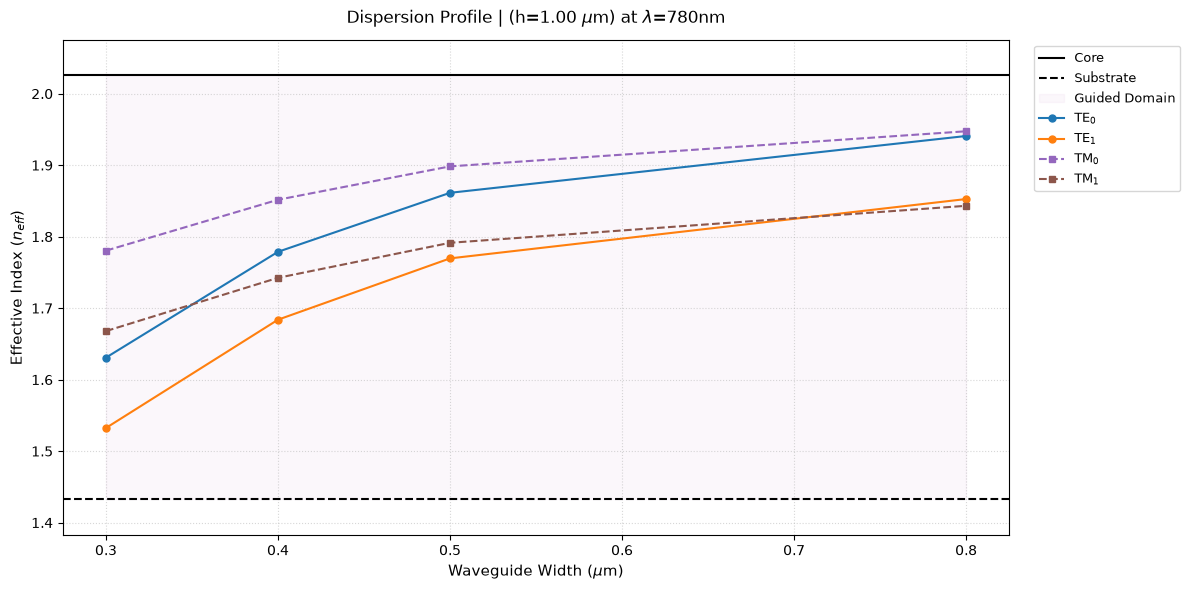

2026-07-23 15:57:38,569 - root - INFO - [Mode Analysis] Visualized distribution out to 780nm_wgW_0.80_wgH_1.00um.png


In [5]:
# ---- Waveguide Mode Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points|
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the modes_in_geometry function
waveguide.modes_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/mode_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    num_modes       = 4,    # Number of modes computed by the Tidy3D solver

    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

2026-07-23 15:57:45,821 - media.medium_helper - INFO - [Medium] Loading si3n4 cached fit from Luke_Si3N4.json...
2026-07-23 15:57:45,822 - media.medium_helper - INFO - [Medium] Loading sio2 cached fit from Nyakuchena_fusedSilica.json...
2026-07-23 15:57:45,824 - waveguide.confinement_sweep - INFO -      [Confinement] Plotting mean geometry (Width: 0.50 μm, Height: 0.77 μm)...


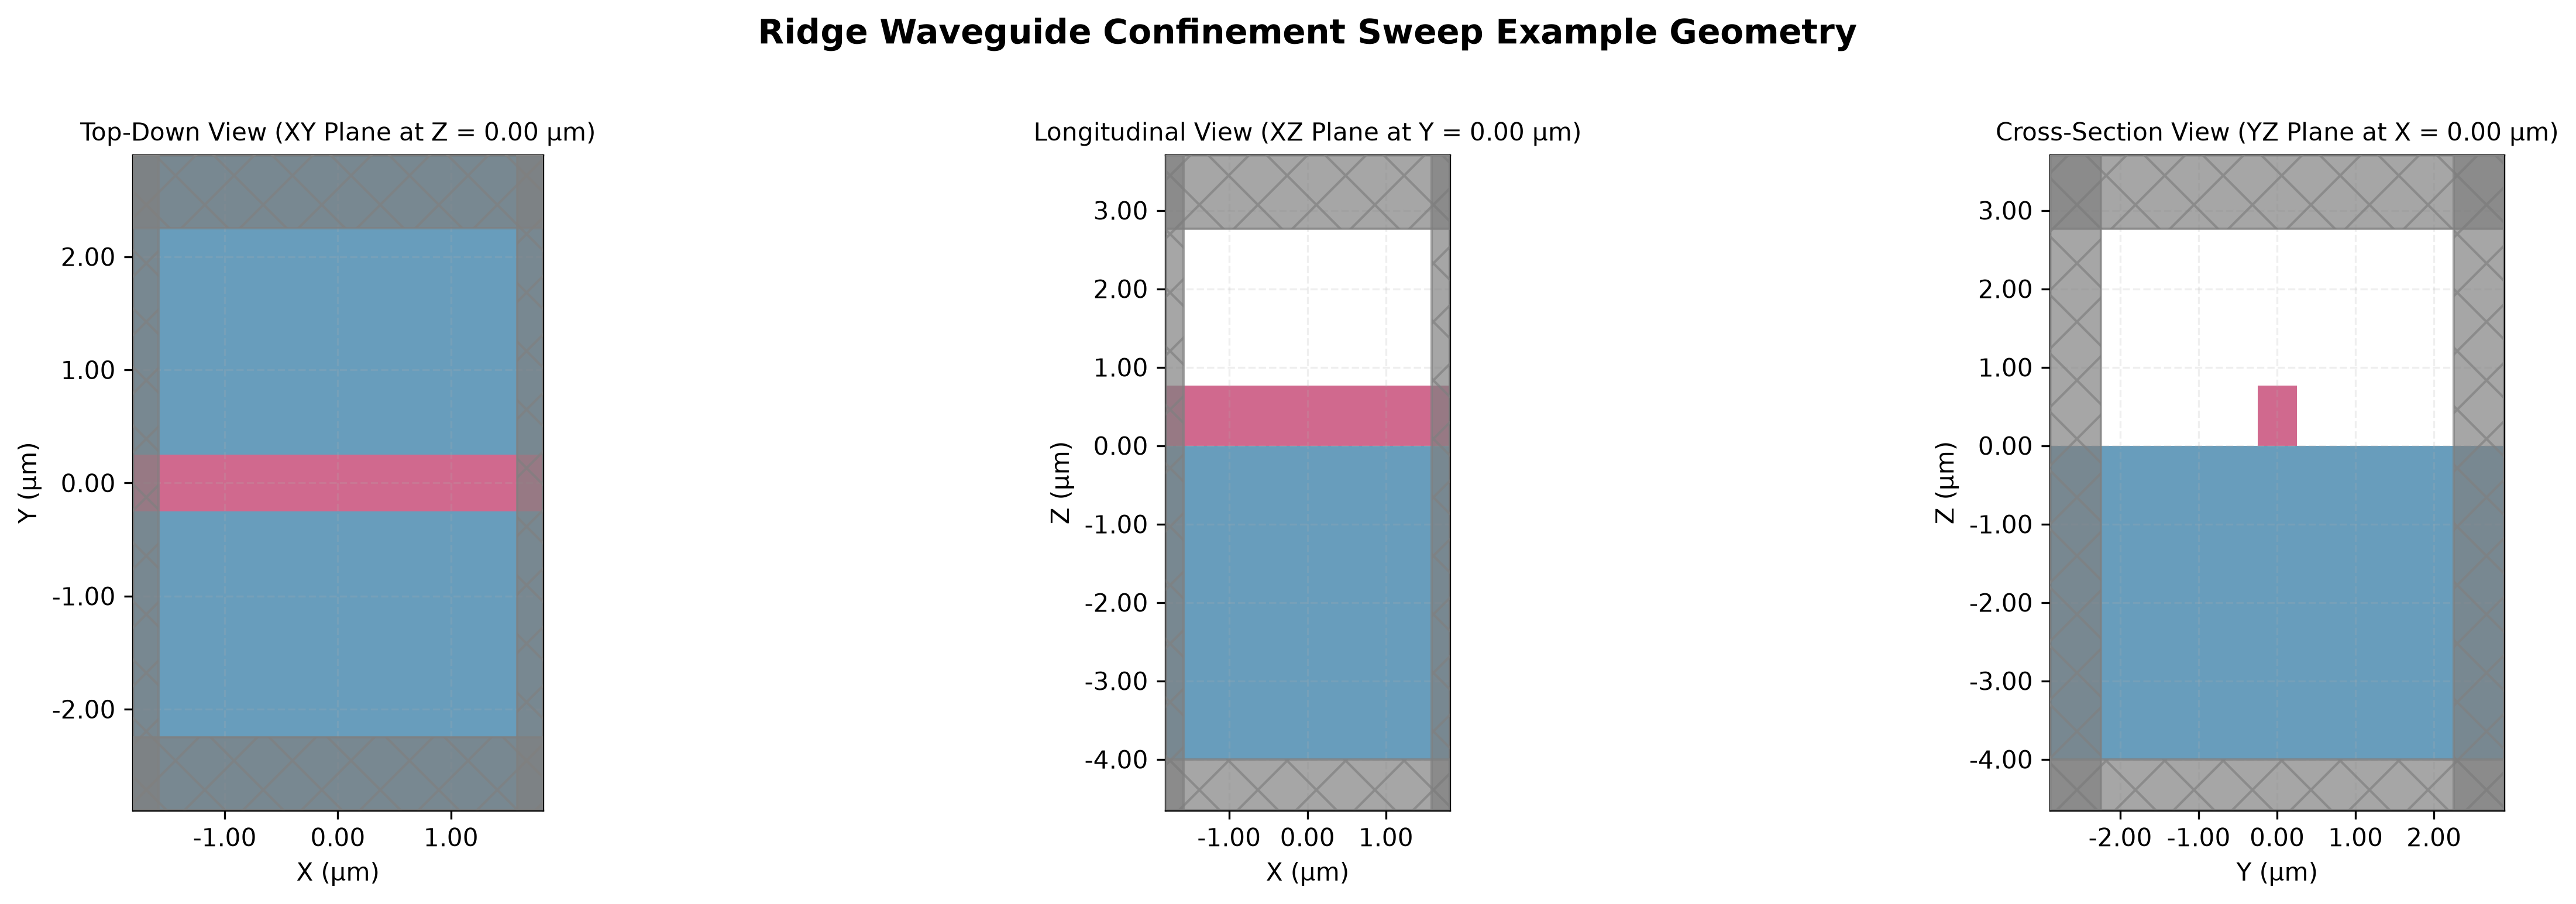

2026-07-23 15:57:46,604 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/waveguide/confinement_sweep/geometries/example_geometry.png
2026-07-23 15:57:46,605 - waveguide.confinement_sweep - INFO - Starting confinement sweep across 3 heights and 4 widths.
    [Confinement] Running geometric width sweep for fixed H = 0.500 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 58.6%, A_eff = 1.977 μm²
    [Confinement] Width 0.40 μm: Gamma = 77.6%, A_eff = 1.755 μm²
    [Confinement] Width 0.50 μm: Gamma = 88.1%, A_eff = 1.745 μm²
    [Confinement] Width 0.80 μm: Gamma = 93.8%, A_eff = 2.230 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H0.500um.png


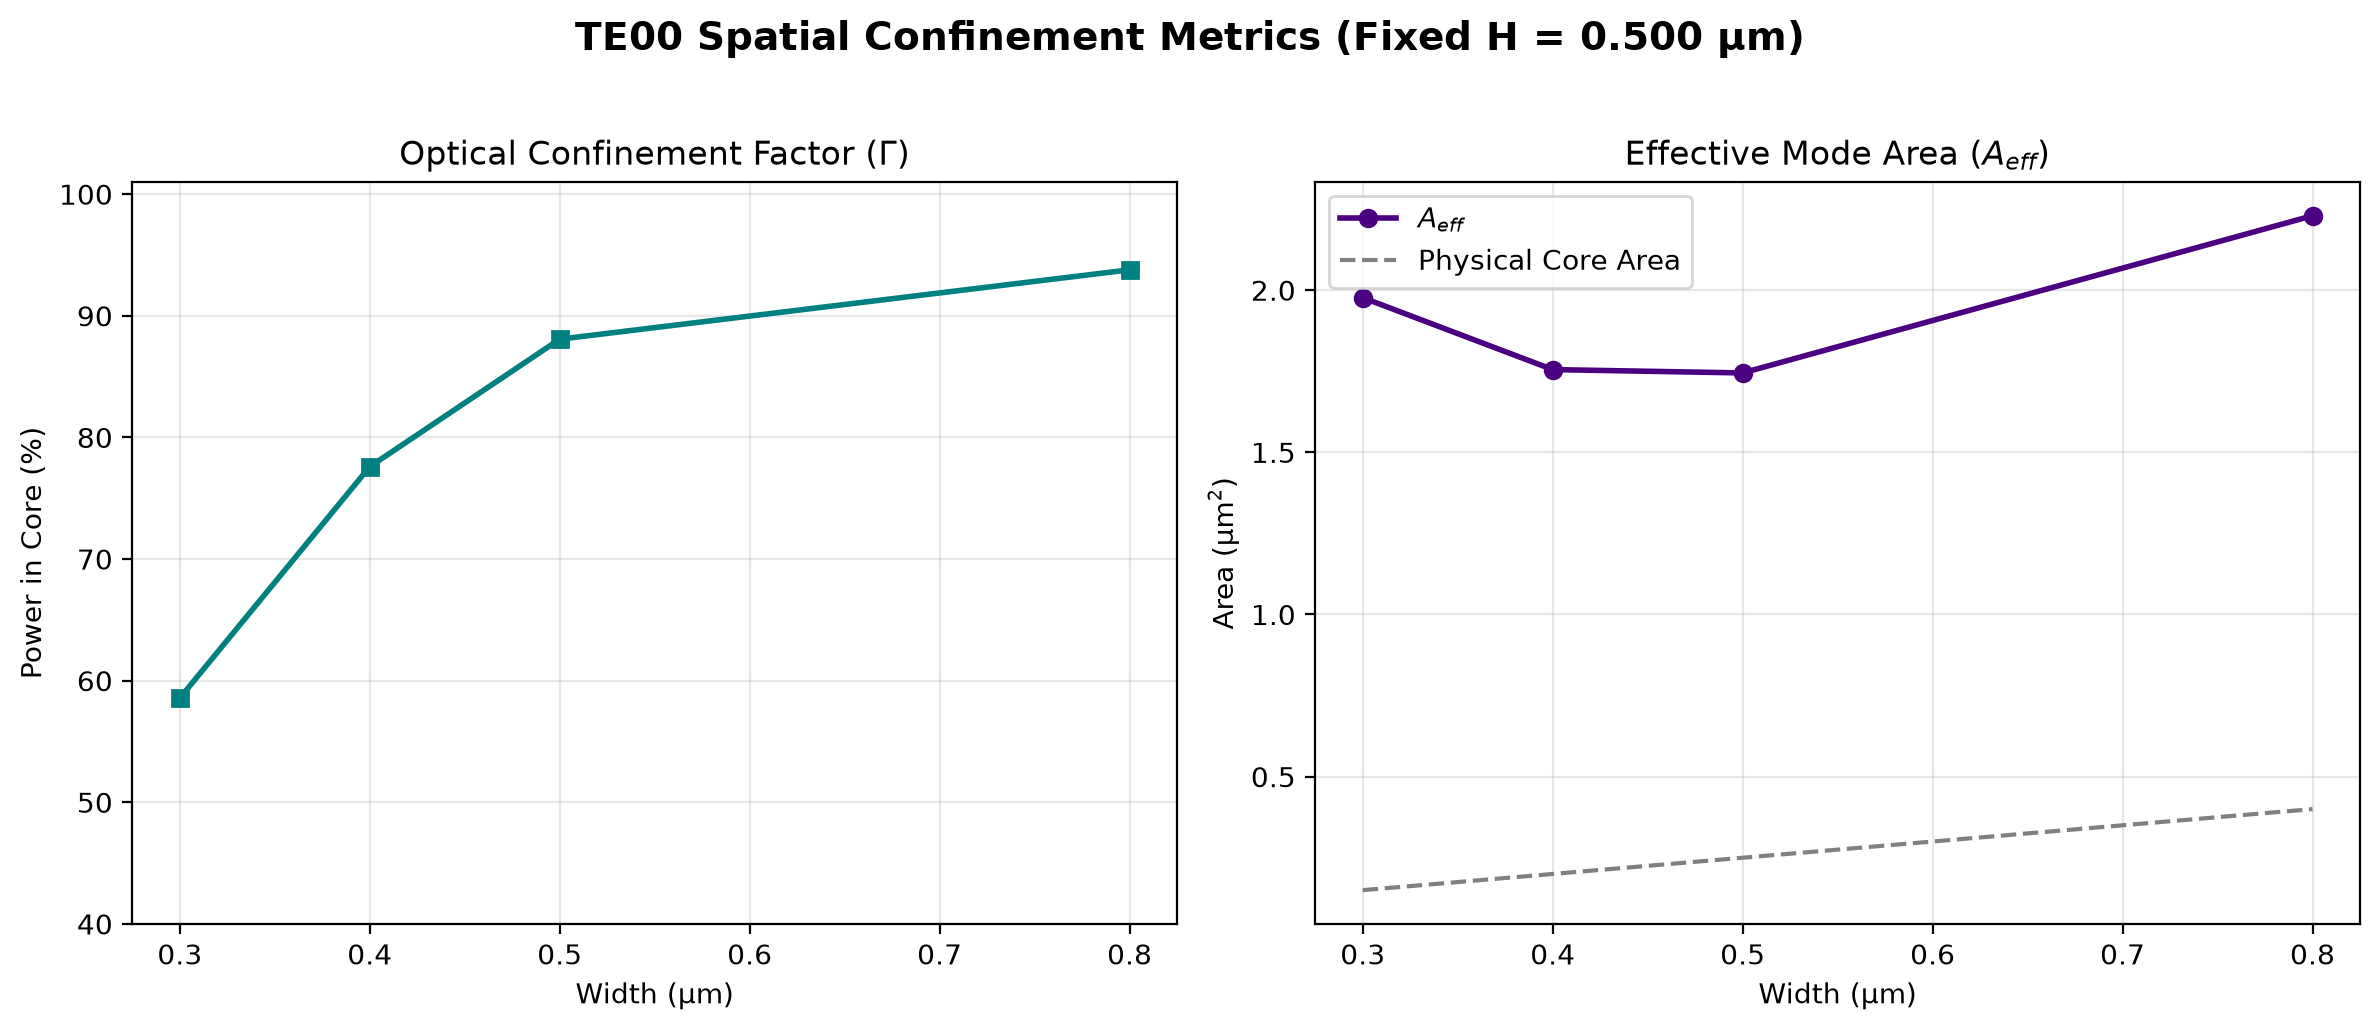

    [Confinement] Running geometric width sweep for fixed H = 0.800 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 62.8%, A_eff = 2.606 μm²
    [Confinement] Width 0.40 μm: Gamma = 80.8%, A_eff = 2.400 μm²
    [Confinement] Width 0.50 μm: Gamma = 90.9%, A_eff = 2.419 μm²
    [Confinement] Width 0.80 μm: Gamma = 96.3%, A_eff = 3.124 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H0.800um.png


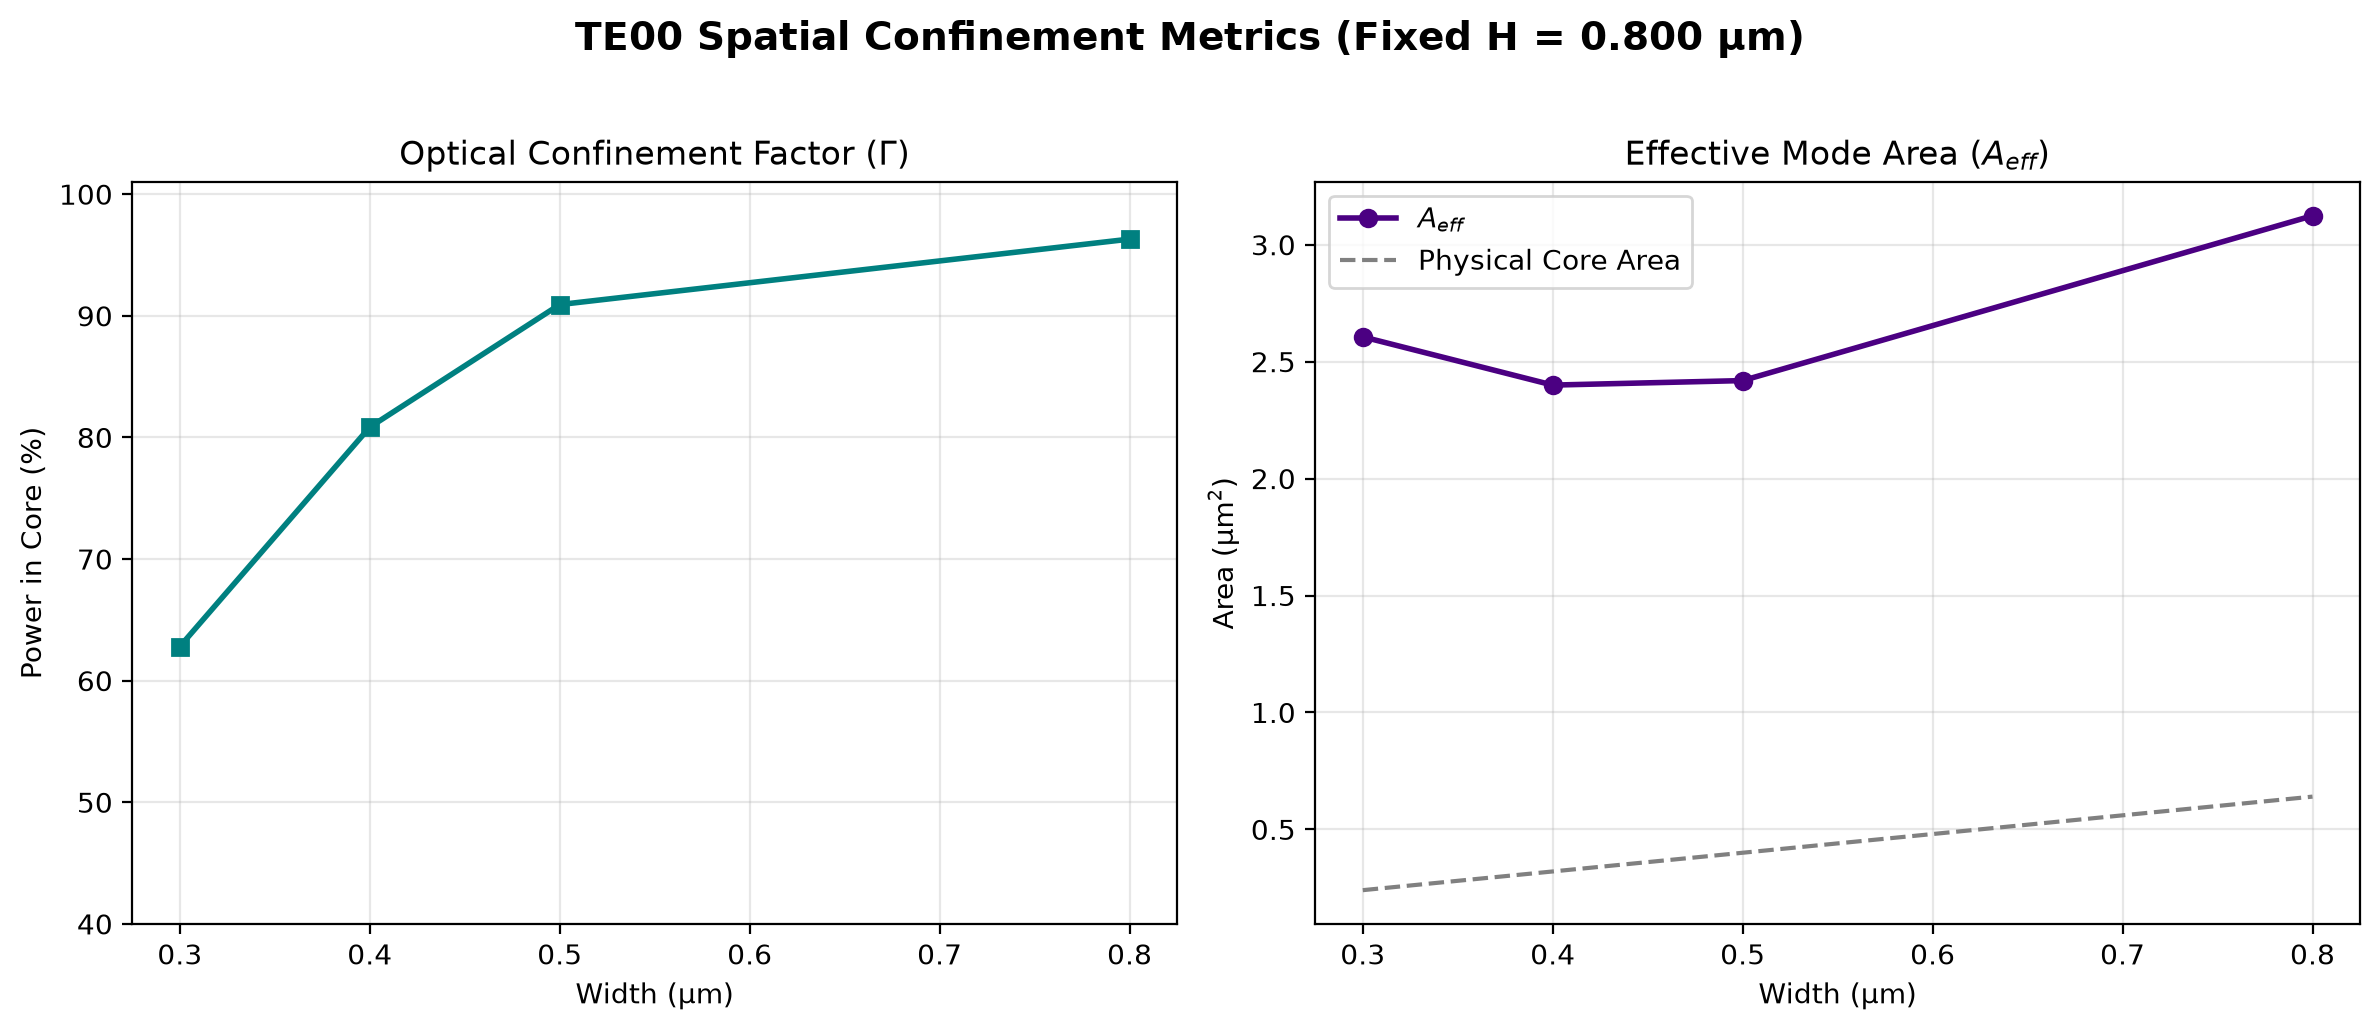

    [Confinement] Running geometric width sweep for fixed H = 1.000 μm at λ = 0.780 μm...
    [Confinement] Width 0.30 μm: Gamma = 63.8%, A_eff = 3.104 μm²
    [Confinement] Width 0.40 μm: Gamma = 81.6%, A_eff = 2.893 μm²
    [Confinement] Width 0.50 μm: Gamma = 91.6%, A_eff = 2.929 μm²
    [Confinement] Width 0.80 μm: Gamma = 96.9%, A_eff = 3.794 μm²
    --> Saved plot: example_results/waveguide/confinement_sweep/confinement_metrics_H1.000um.png


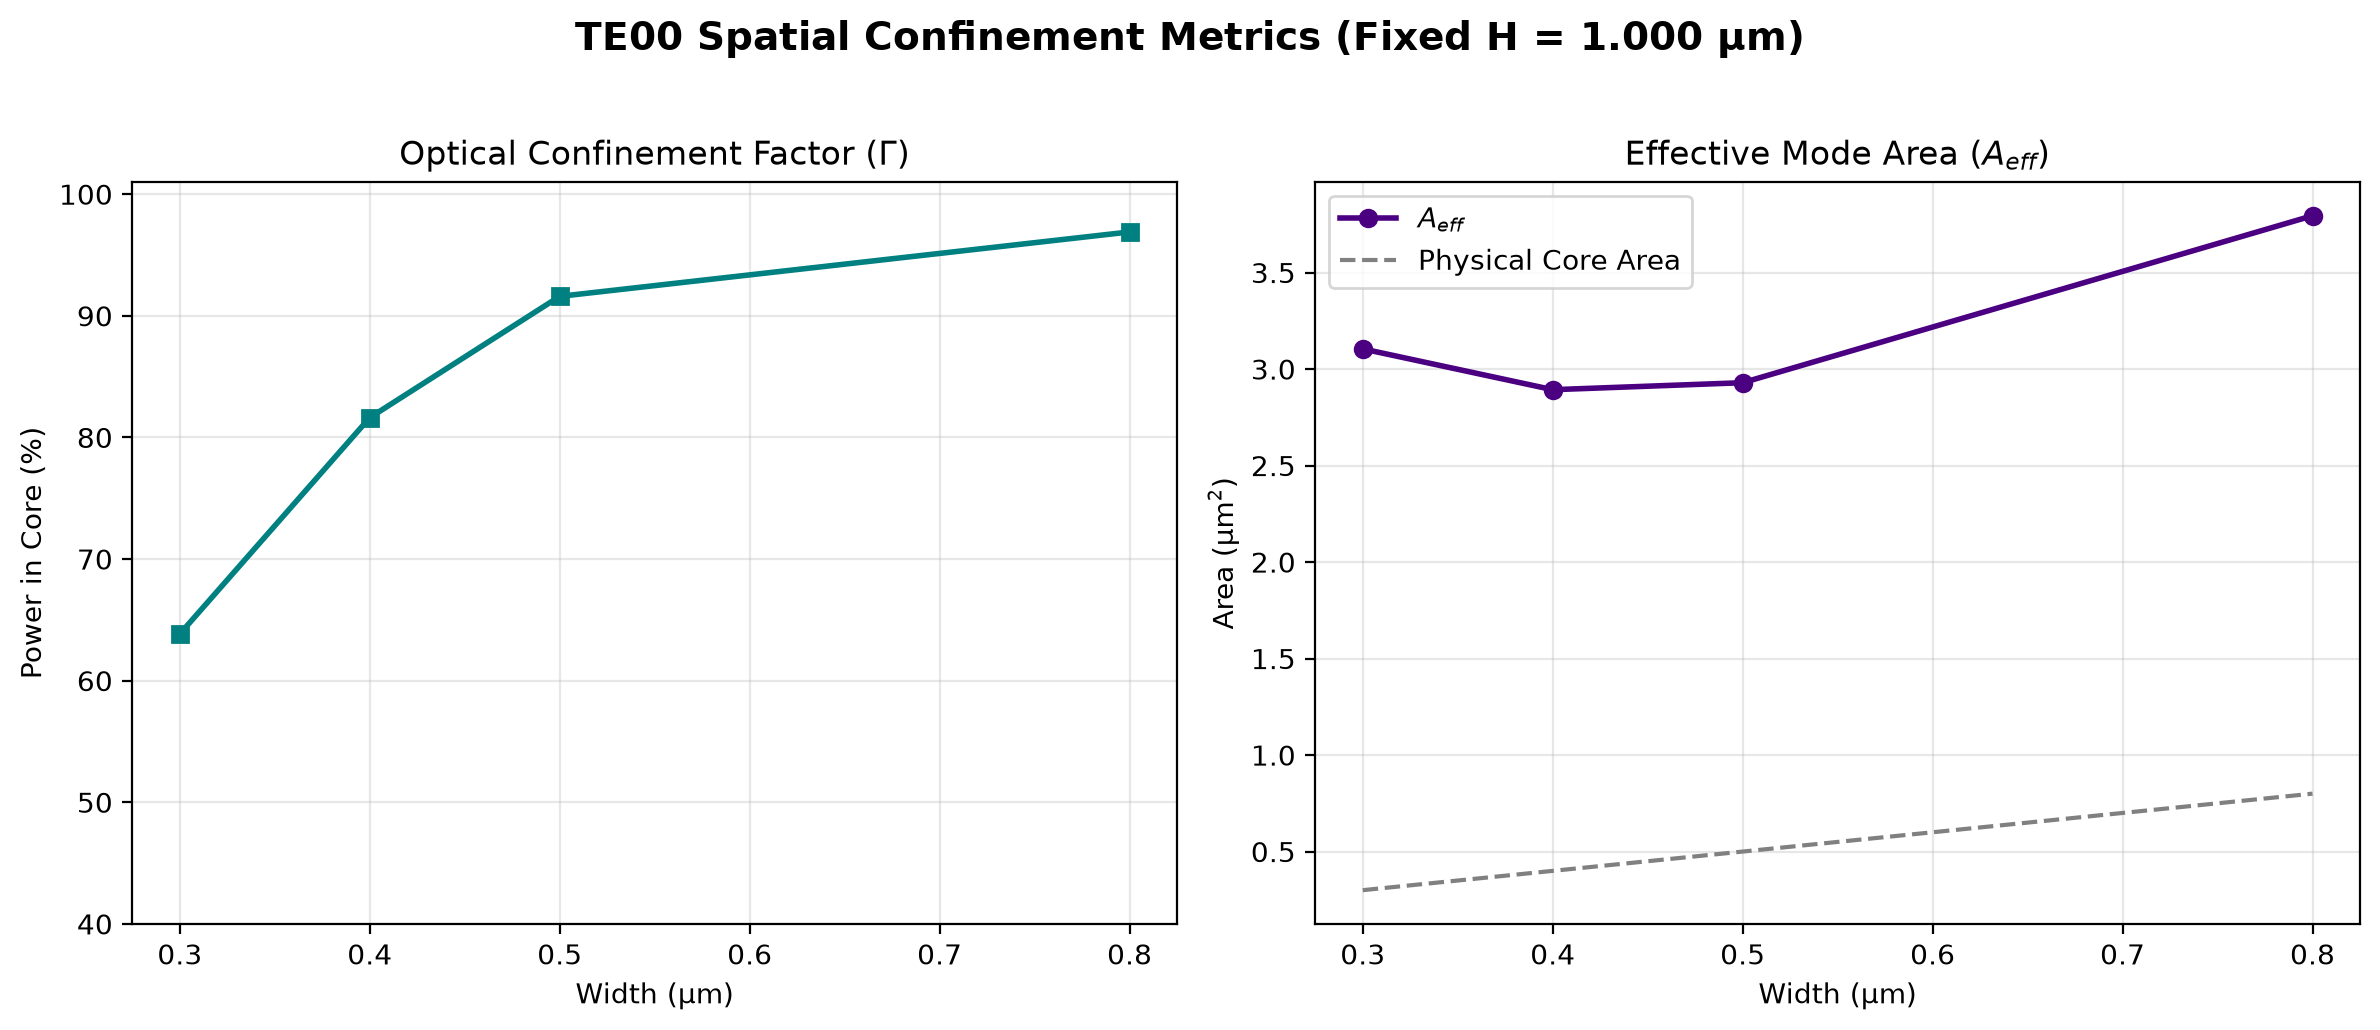

{0.5: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(58.57205813865415),
   np.float64(77.59195158643439),
   np.float64(88.07682295576217),
   np.float64(93.77876685623761)],
  [np.float64(1.9768622554175688),
   np.float64(1.7550940749544421),
   np.float64(1.7448151608037832),
   np.float64(2.2295091546875674)]),
 0.8: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(62.80741251346086),
   np.float64(80.84286641493156),
   np.float64(90.92283720183018),
   np.float64(96.30381357338959)],
  [np.float64(2.606042467050007),
   np.float64(2.3997229612250672),
   np.float64(2.4190223412108396),
   np.float64(3.1239540410132034)]),
 1.0: ([0.3, 0.4, 0.5, 0.8],
  [np.float64(63.84066024601489),
   np.float64(81.6256885511676),
   np.float64(91.59869930272437),
   np.float64(96.8934238593046)],
  [np.float64(3.1044538665181745),
   np.float64(2.8930052160264865),
   np.float64(2.9292354019097435),
   np.float64(3.7943781318947916)])}

In [6]:
# ---- Waveguide Confinement Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.confinement_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/confinement_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    
    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

2026-07-24 00:47:49,440 - media.medium_helper - INFO - [Medium] Loading si3n4 cached fit from Luke_Si3N4.json...
2026-07-24 00:47:49,443 - media.medium_helper - INFO - [Medium] Loading sio2 cached fit from Nyakuchena_fusedSilica.json...
2026-07-24 00:47:49,445 - waveguide.dispersion_sweep - INFO -      [Dispersion] Plotting mean geometry (Width: 0.50 μm, Height: 0.77 μm)...


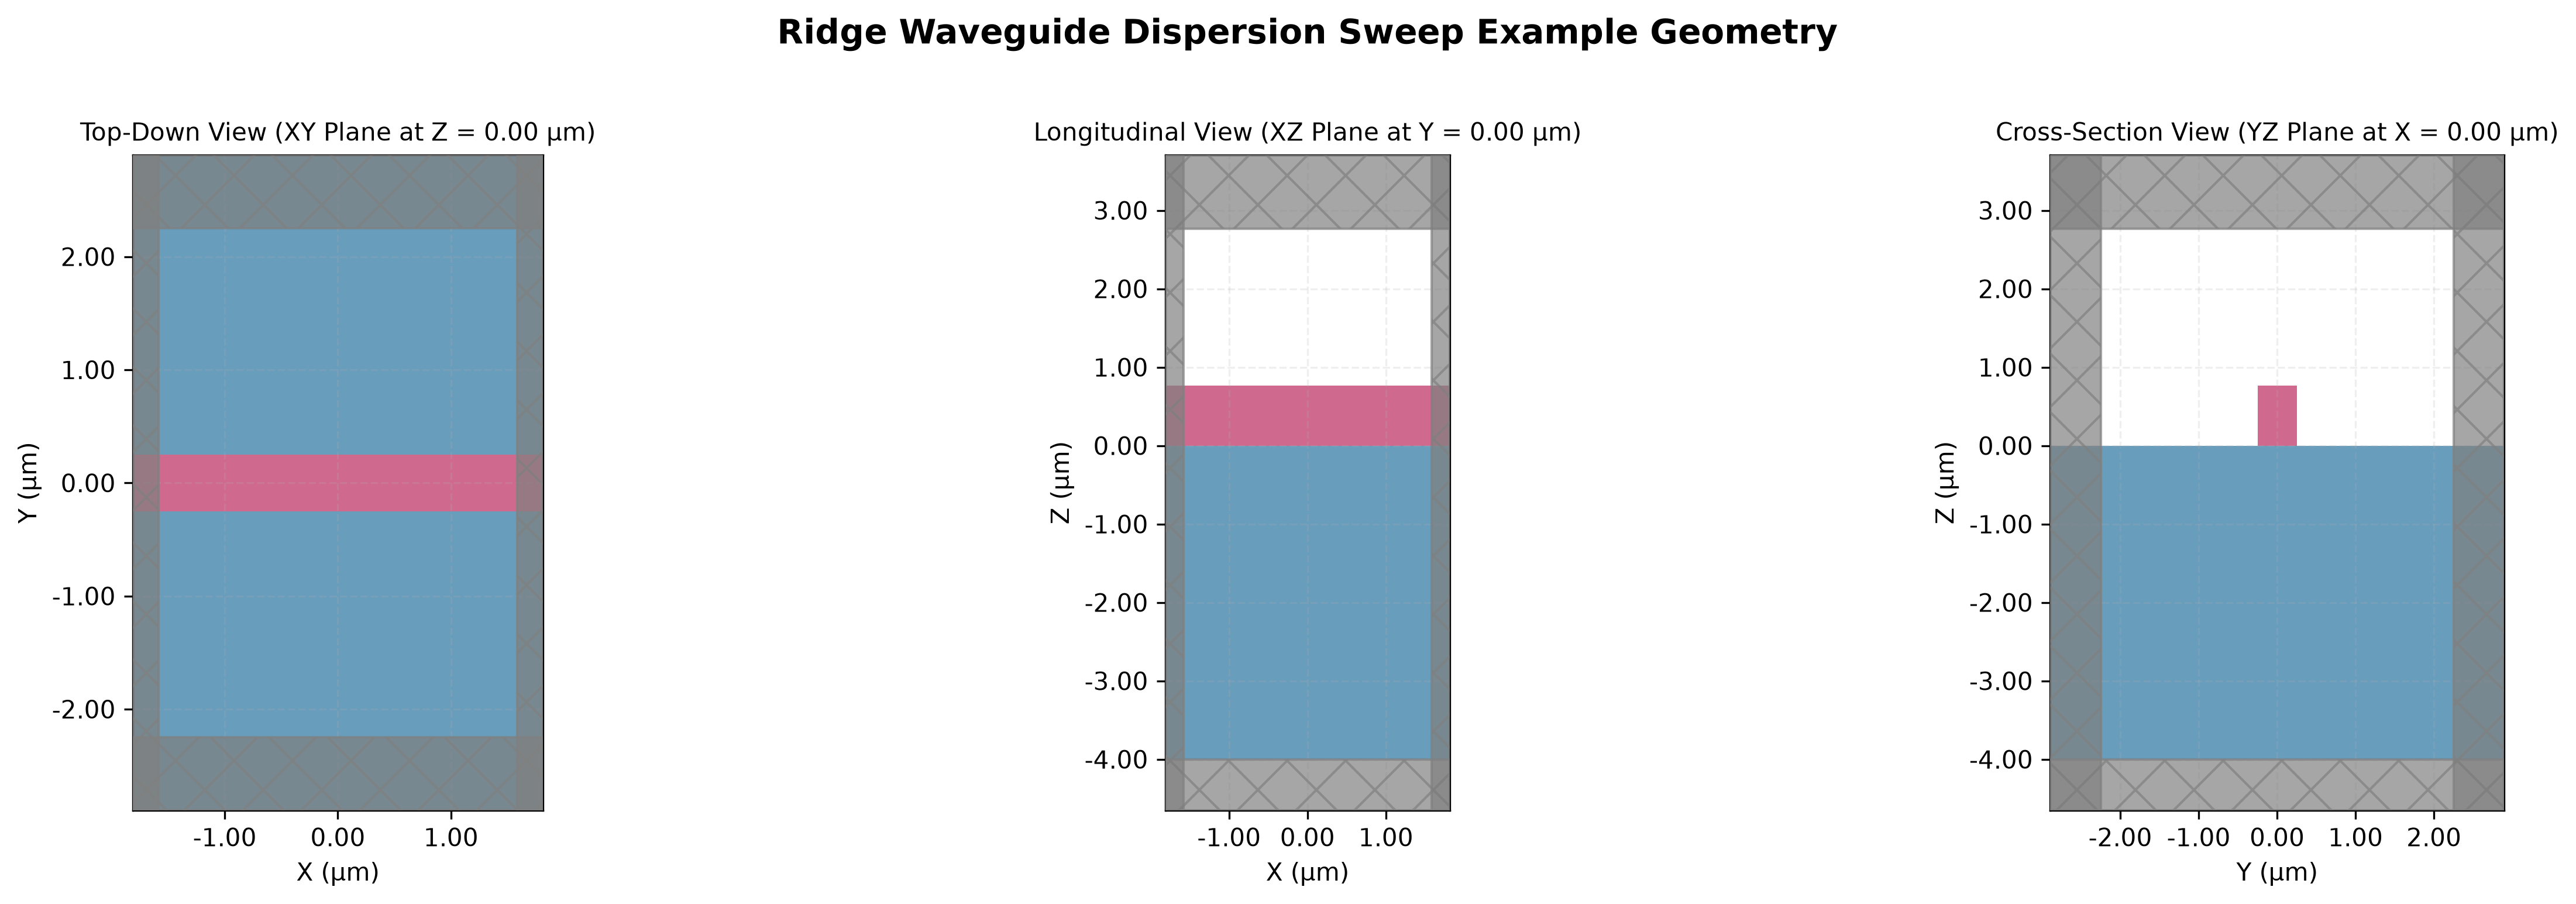

2026-07-24 00:47:50,486 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/waveguide/dispersion_sweep/geometries/example_dispersion_geometry.png
2026-07-24 00:47:50,491 - waveguide.dispersion_sweep - INFO - Starting dispersion sweep across 4 widths and 3 heights.
    [Dispersion] Sweeping heights for fixed W = 0.300 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = -14.80 ps/(nm·km) [SINGLE MODE]
    [Dispersion] Height 0.80 μm: D = 0.19 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 2.73 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.300um.png


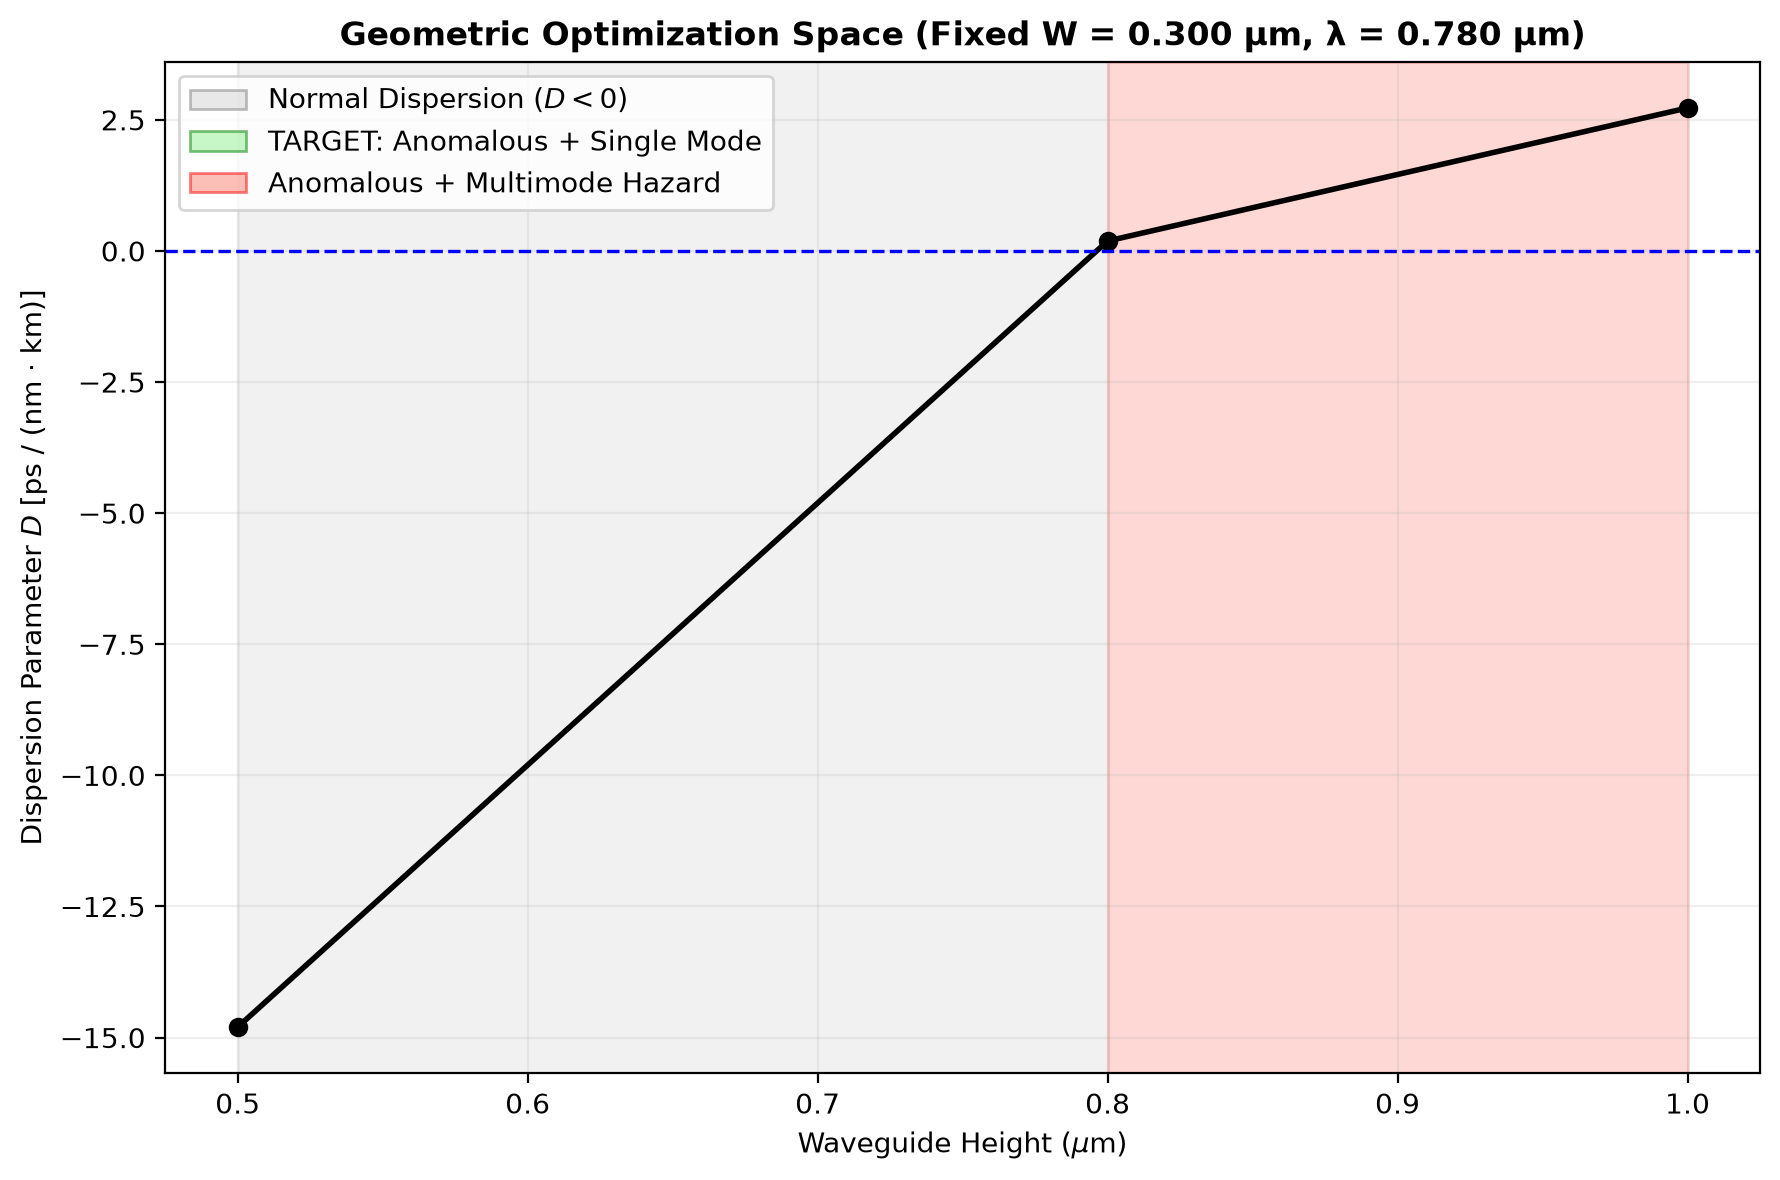

    [Dispersion] Sweeping heights for fixed W = 0.400 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 6.83 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 8.65 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 8.46 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.400um.png


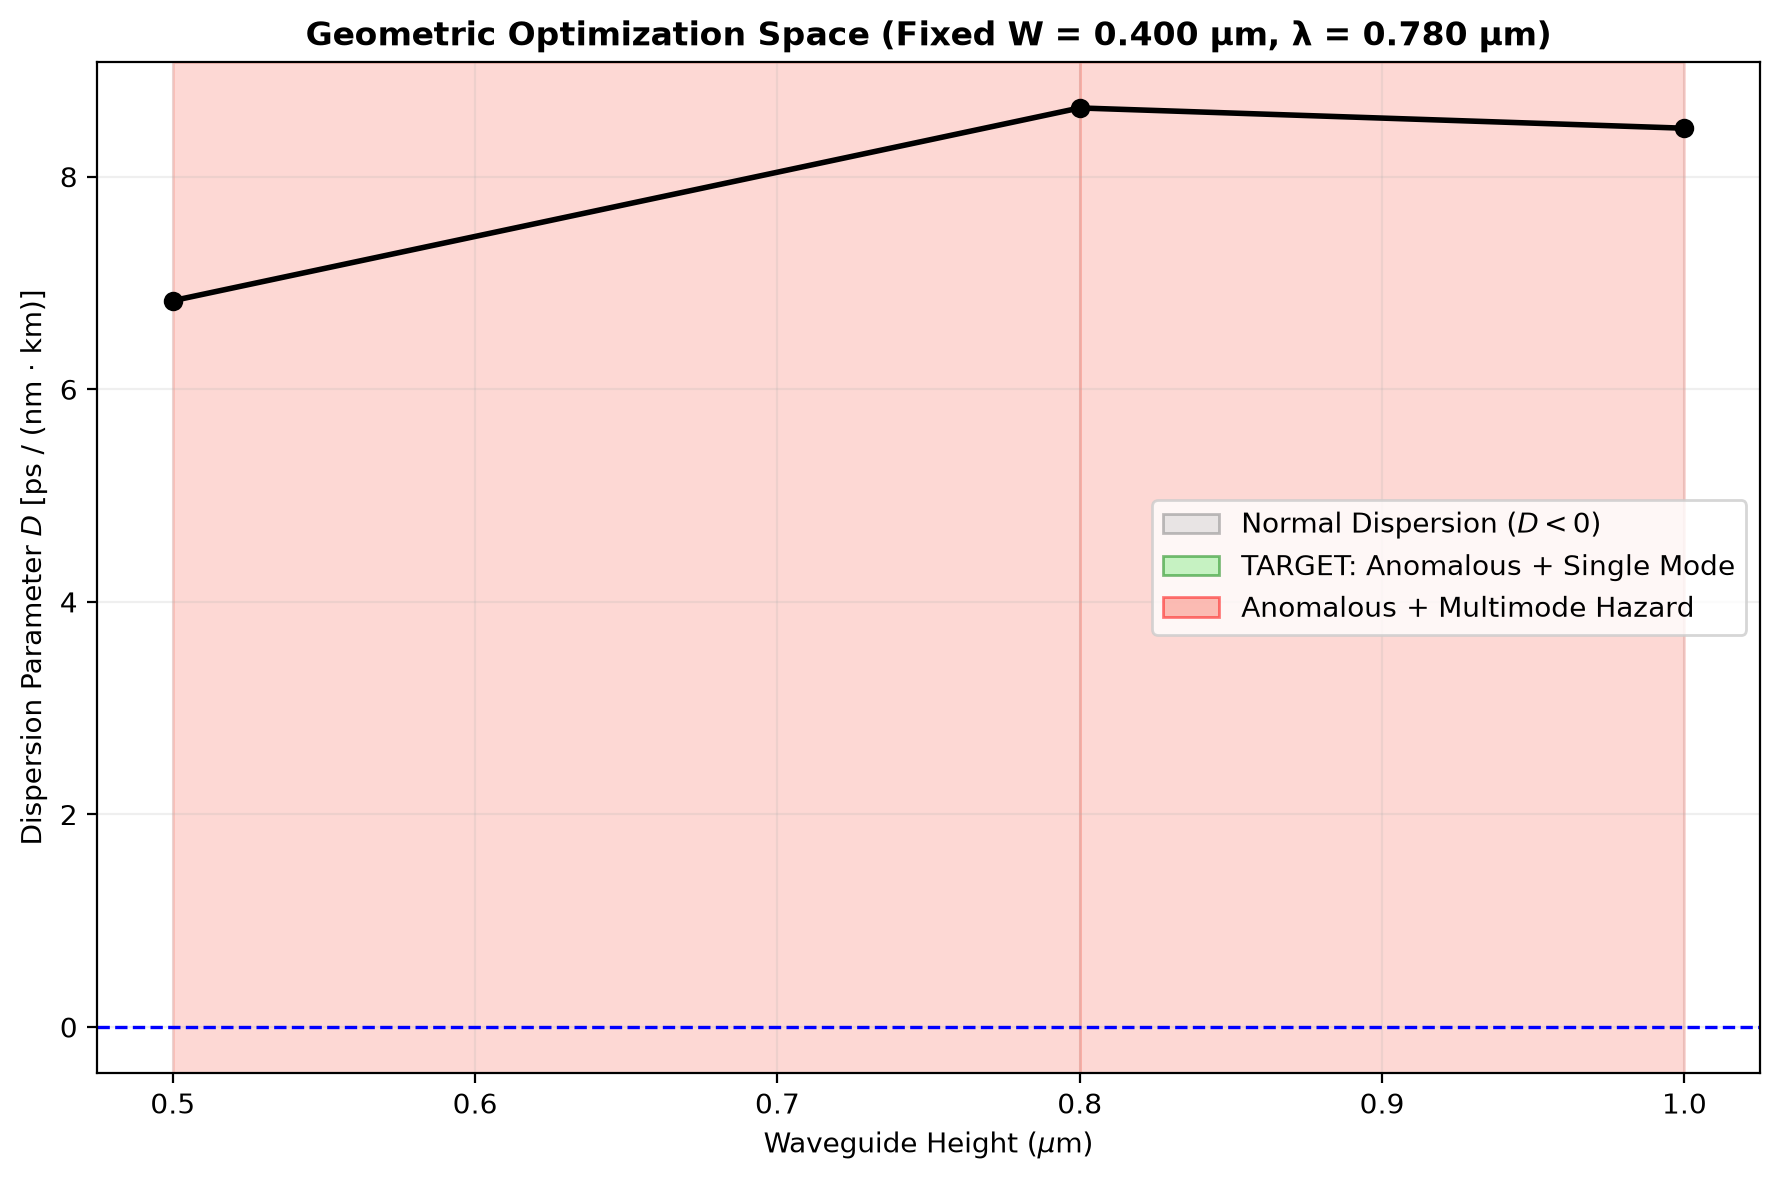

    [Dispersion] Sweeping heights for fixed W = 0.500 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 5.62 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 5.63 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = 5.16 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.500um.png


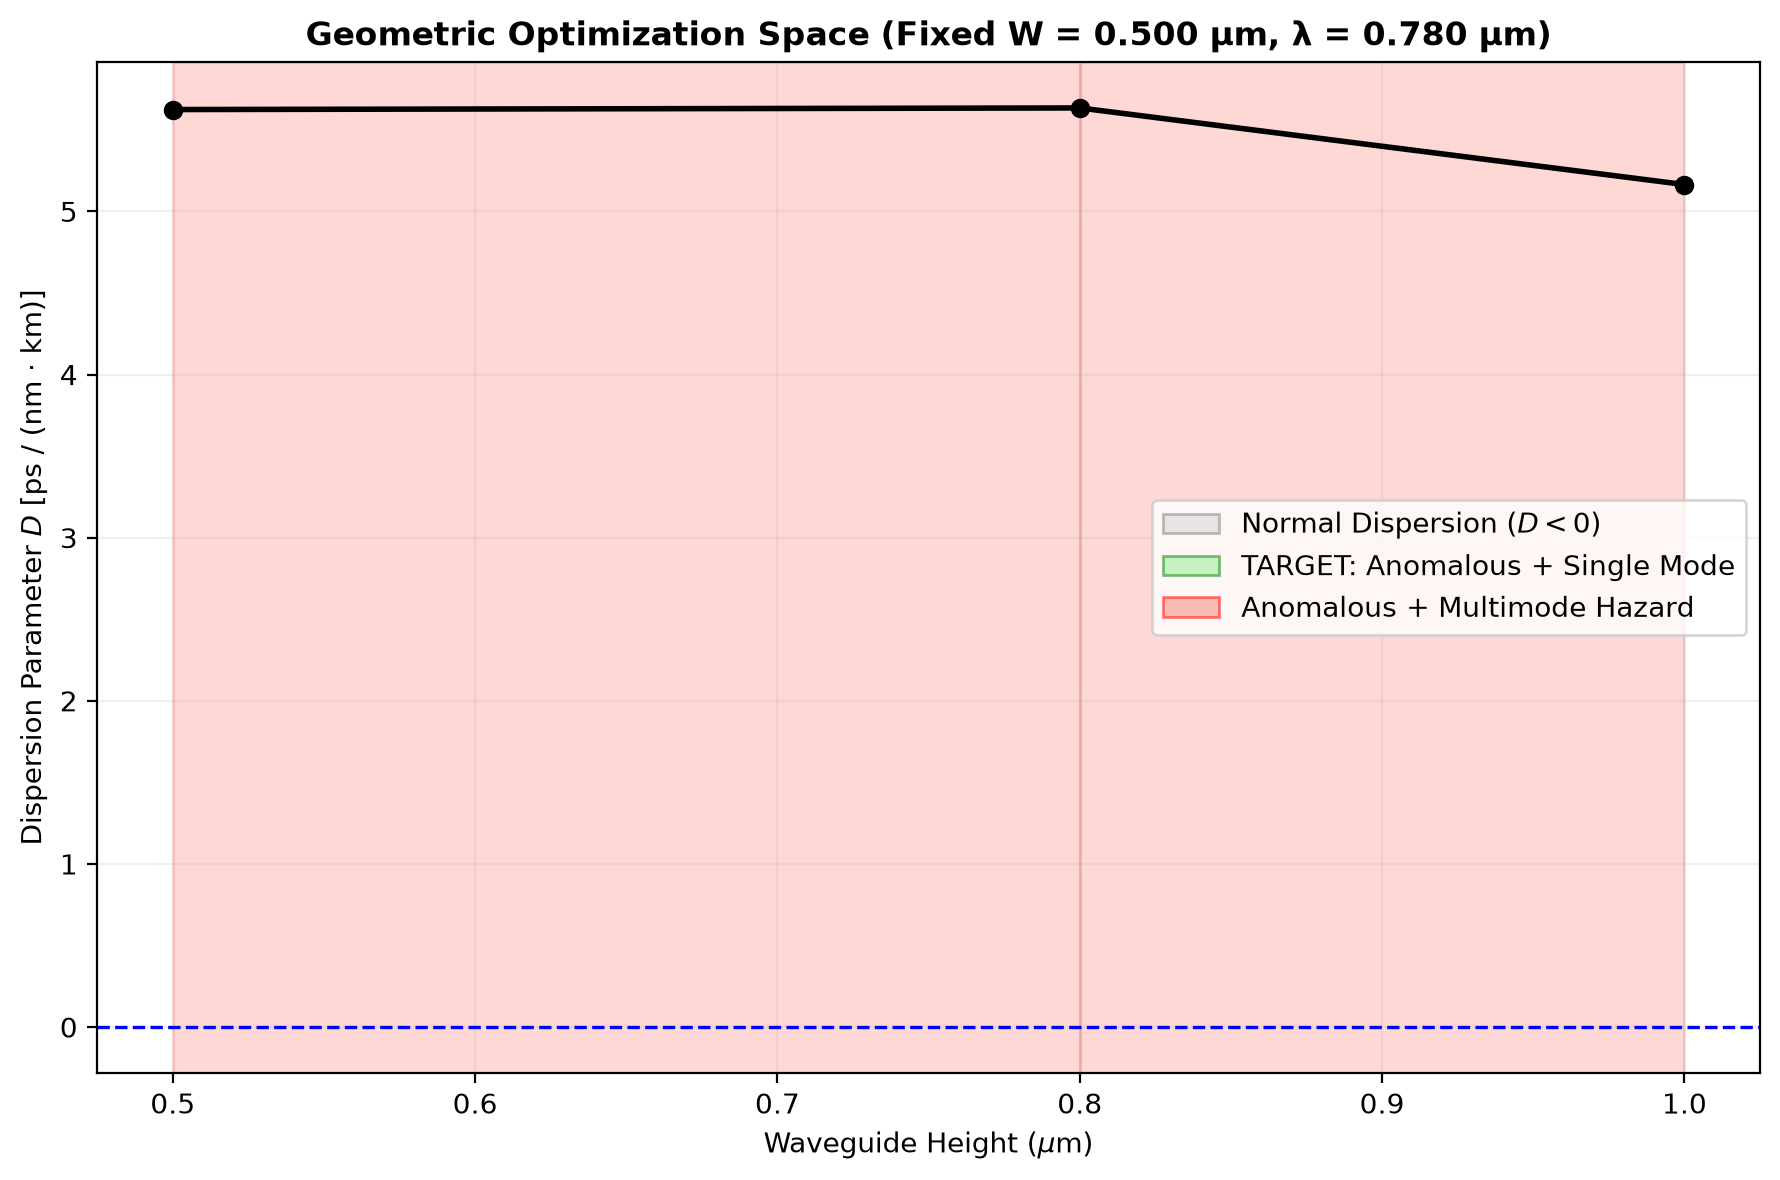

    [Dispersion] Sweeping heights for fixed W = 0.800 μm at λ = 0.780 μm...
    [Dispersion] Height 0.50 μm: D = 0.44 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 0.80 μm: D = 0.23 ps/(nm·km) [MULTIMODE]
    [Dispersion] Height 1.00 μm: D = -0.18 ps/(nm·km) [MULTIMODE]
  --> Saved plot: example_results/waveguide/dispersion_sweep/dispersion_metrics_W0.800um.png


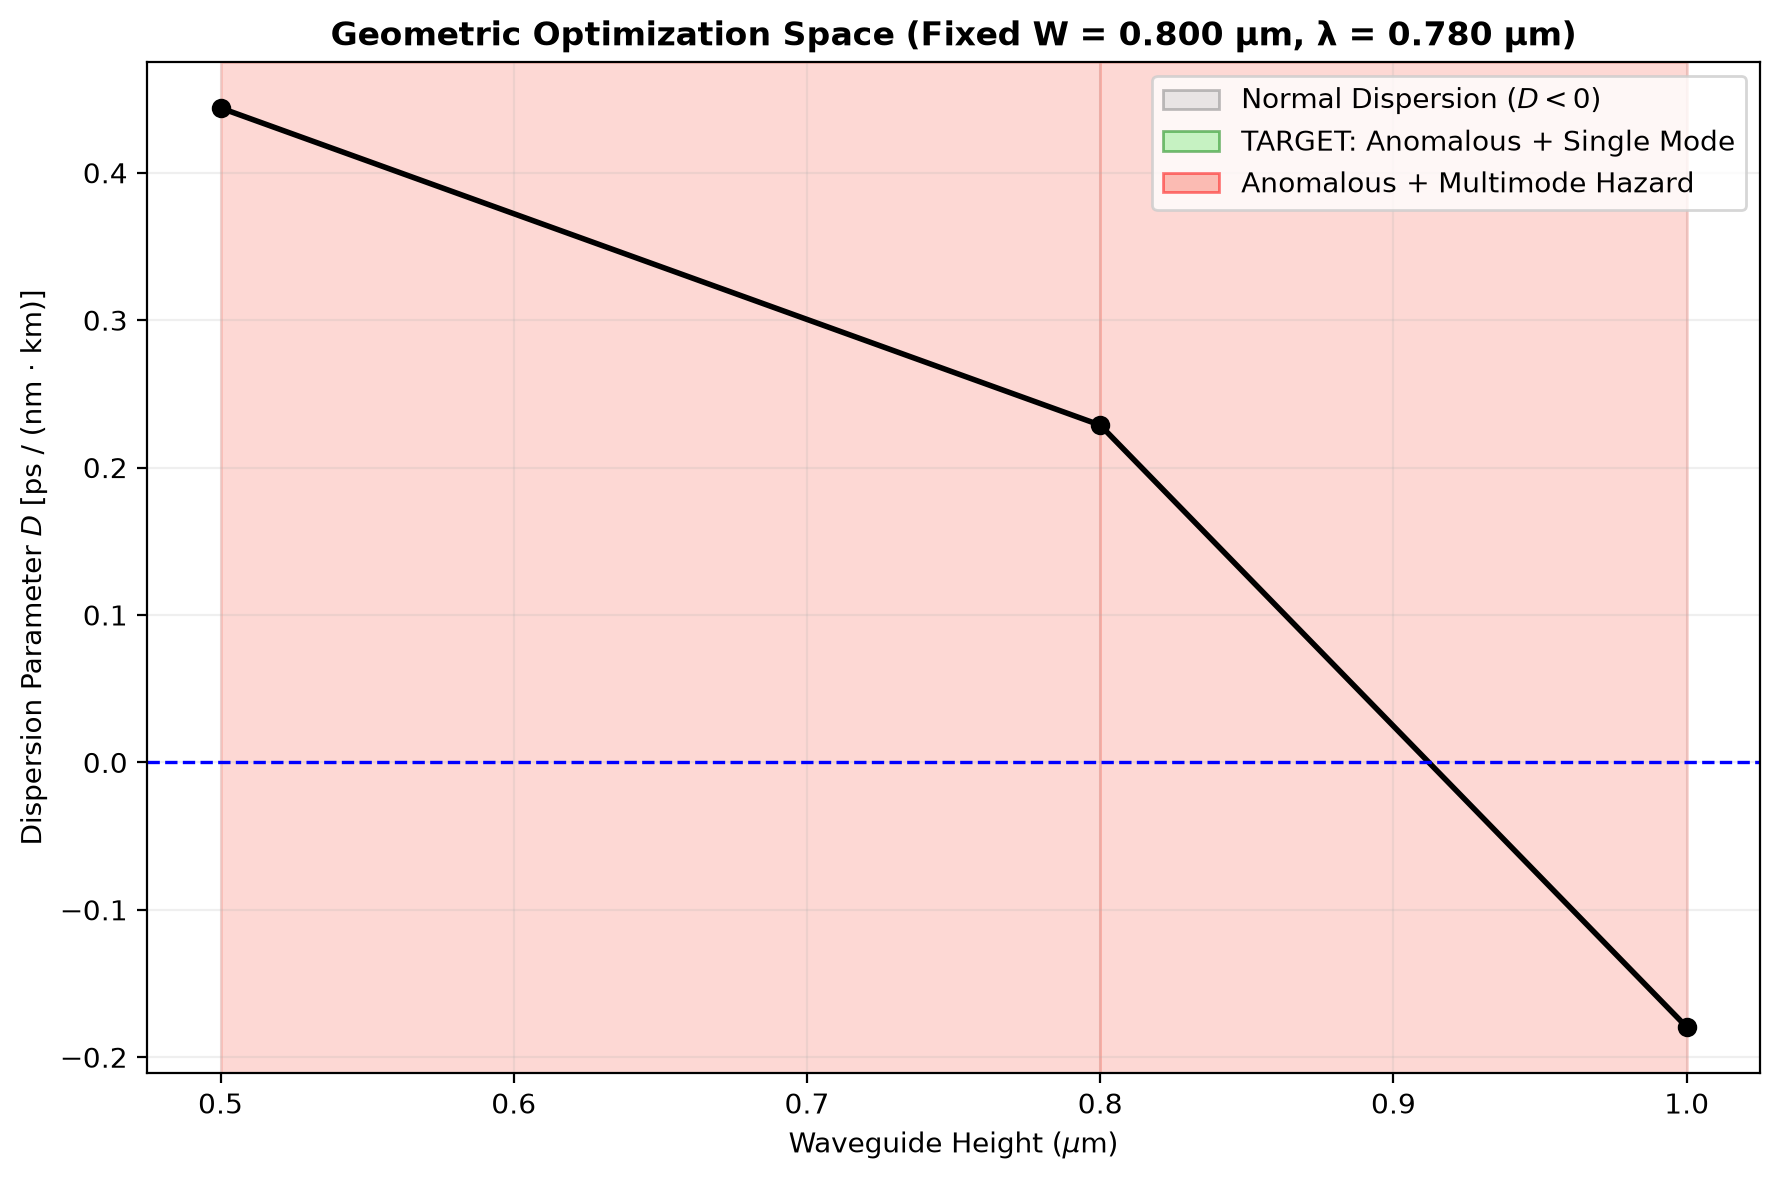

{0.3: ([0.5, 0.8, 1.0],
  [-14.799158229887393, 0.1891441966625106, 2.7263436560082743],
  [True, False, False]),
 0.4: ([0.5, 0.8, 1.0],
  [6.833271767229437, 8.64658805422244, 8.45581311313369],
  [False, False, False]),
 0.5: ([0.5, 0.8, 1.0],
  [5.624250055253218, 5.634105216151421, 5.164478834666842],
  [False, False, False]),
 0.8: ([0.5, 0.8, 1.0],
  [0.4439456969188655, 0.22876448897390056, -0.1795503722223724],
  [False, False, False])}

In [1]:
# ---- Waveguide Dispersion Analysis and Sweep ---- #

import waveguide
from media import medium_helper

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = medium_helper.get_medium("si3n4",(0.600, 1.200))
SiO2 = medium_helper.get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.dispersion_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    sub_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/dispersion_sweep/",

    wavelength_um   = target_wavelength_um,
    substrate_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    
    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)